# Setup

In [1]:
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path
sys.path.append(str(Path.cwd().resolve().parent))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf
from tensorflow import keras
from sklearn.utils import shuffle

from utils.feature_importance_utils import (
    permutation_importance_global_sequence,
)

from utils.feature_utils import (
    get_condition_aware_labels,
    normalize_train_labels,
    extract_features_blockless,
)

print("tf:", tf.__version__)
print("keras:", keras.__version__)

tf: 2.20.0
keras: 3.13.2


# Model comparison

## Extract test features

In [3]:
test_data = []
N_AGENTS = 500
num_blocks = 12
max_num_trials = 78
LIST_OF_MODELS = ['rlf', 'wm']
for m in LIST_OF_MODELS:
  filename = f"../data/{m}_6s3a/rand500_st11_{N_AGENTS}a_{num_blocks}b_{max_num_trials}t_{m}.csv"
  data = pd.read_csv(filename)
  data['model_type'] = m
  test_data.append(data)

test_data = pd.concat(test_data)

In [4]:
all_test_features = []
all_test_labels = []

feature_list = [
    "actions",
    "rewards",
    "stim_iter",
    "isswitch",
    "prev_action",
    "delay_since_last_stimuli",
]
sorted_col = ["agentid", "block_no", "stimuli"]
for idx, (model, data) in enumerate(test_data.groupby("model_type")):
    fd_iter = data
    fd_iter["isswitch"] = fd_iter["trials"].apply(lambda x: 1 if x == 0 else 0)
    fd_iter["prev_action"] = (
        data.groupby(["agentid", "block_no"])["actions"]
        .shift(1)
        .fillna(-1)
        .astype(int)
        .to_list()
    )
    fd_iter_order = fd_iter.sort_values(by=sorted_col) if True else fd_iter
    features = extract_features_blockless(fd_iter_order, feature_list, [])
    all_test_features.append(features)
    all_test_labels.extend([idx] * len(features))
    print(model, features.shape)

all_test_features = tf.concat(all_test_features, 0)
all_test_labels_cat = tf.keras.utils.to_categorical(
    all_test_labels, num_classes=test_data.model_type.nunique()
)

all_test_features, all_test_labels_cat = shuffle(
    all_test_features.numpy(), all_test_labels_cat, random_state=0
)
print(all_test_features.shape, all_test_labels_cat.shape)

rlf (500, 936, 6)
wm (500, 936, 6)
(1000, 936, 6) (1000, 2)


## Load trained model

In [6]:
model_name = "rlf_wm_27000a_B256_U96_D0.185_D0.0112_D0.01_0.0016_model.keras"
model_classifier = tf.keras.models.load_model(f"../models/{model_name}", compile=True)

## Evaluation

In [ ]:
ranking = permutation_importance_global_sequence(
    model=model_classifier,
    X_val=all_test_features,
    y_val=all_test_labels_cat,
    feature_names=feature_list,
    n_repeats=3,
    batch_size=64,
    shuffle_mode="sequence",
    block_size=32,
    random_state=123
)

Baseline loss: 0.17366033792495728
Permutation feature actions
Permutation loss: 1.9209743738174438
Permutation loss: 2.046502113342285
Permutation loss: 2.035888910293579
Permutation feature rewards
Permutation loss: 2.0748560428619385
Permutation loss: 2.1394388675689697
Permutation loss: 2.2116761207580566
Permutation feature stim_iter
Permutation loss: 0.17366033792495728
Permutation loss: 0.17366033792495728
Permutation loss: 0.17366033792495728
Permutation feature isswitch
Permutation loss: 0.2133299857378006


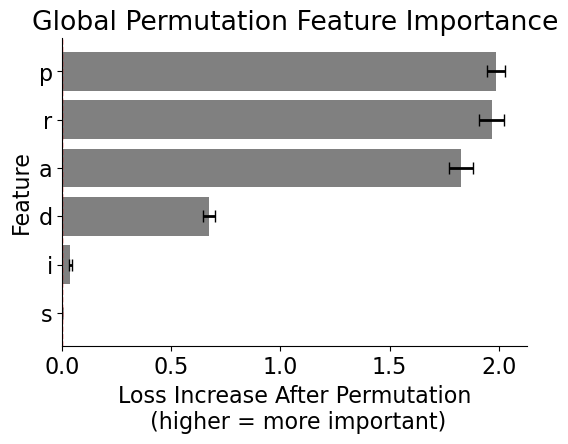

In [12]:
plt.rcParams.update({"font.size": 16})

fig, ax = plt.subplots(figsize=(6, 4))
ax = sns.barplot(
    data=ranking,
    x="importance_mean",
    y="feature",
    color="grey",
    ax=ax,
)
# add error bars if present
if "importance_std" in ranking.columns:
    ax.errorbar(
        x=ranking["importance_mean"],
        y=range(len(ranking)),
        xerr=ranking["importance_std"],
        fmt="none",
        ecolor="black",
        capsize=4,
        lw=2
    )
ax.axvline(0, color="red", linestyle="--", linewidth=1)
ax.set_title(f"Global Permutation Feature Importance") # ({k}% missing)")
ax.set_xlabel("Loss Increase After Permutation\n (higher = more important)")
short_labels = [l.get_text()[:1] for l in ax.get_yticklabels()]
ax.set_yticklabels(short_labels, rotation=0)
ax.set_ylabel("Feature")
sns.despine(ax=ax)
fig.savefig(
    f"/Users/ccnlab/Documents/project_dl4rl/Tutorial/mi_importance.png",
    dpi=600,
    bbox_inches="tight",
)

# Extract test features for parameter estimation/LaseNet

In [ ]:
model_name = "rlf"
N_AGENTS = 500
num_blocks = 12
max_num_trials = 78
suffix = model_name
filename = f"../data/{model_name}_6s3a/rand500_st11_500a_12b_78t_{suffix}.csv" 
print(filename)
test_data = pd.read_csv(filename)

./data/rlf_6s3a/rand500_st11_500a_12b_78t_rlf.csv


In [3]:
has_switches = test_data.isswitch.nunique() == 2
test_iter = (
    test_data.copy()
)  # .get_iter_acc_with_switches(test_data) if has_switches else get_iter_acc_without_switches(test_data)
test_iter["isswitch"] = test_iter["trials"].apply(lambda x: 1 if x == 0 else 0)
test_iter["prev_action"] = (
    test_data.groupby(["agentid", "block_no"])["actions"]
    .shift(1)
    .fillna(-1)
    .astype(int)
    .to_list()
)
test_iter["delay_since_last_stimuli"] = test_data["delay_since_last_stimuli"].to_list()

masked_to_test_data = {10: test_data.copy(), 25: test_data.copy(), 5: test_data.copy()}
# Randomly mask 10% of the rows in the specified columns to be NaN
cols_to_mask = ["iscorrectaction", "rpe_history", "actions", "rewards"]
maksed_to_test_iter = {f: {} for f in masked_to_test_data.keys()}
num_rows = test_iter.shape[0]
for k in masked_to_test_data.keys():
    mask_size = int(num_rows * k / 100)
    mask_indices = np.random.choice(num_rows, mask_size, replace=False)
    masked_to_test_data[k].loc[mask_indices, cols_to_mask] = np.nan
    maksed_iter = masked_to_test_data[k].copy()
    maksed_iter["isswitch"] = maksed_iter["trials"].apply(lambda x: 1 if x == 0 else 0)
    maksed_iter["prev_action"] = (
        masked_to_test_data[k]
        .groupby(["agentid", "block_no"])["actions"]
        .shift(1)
        .fillna(-1)
        .astype(int)
        .to_list()
    )
    maksed_iter["delay_since_last_stimuli"] = masked_to_test_data[k][
        "delay_since_last_stimuli"
    ].to_list()
    maksed_to_test_iter[k] = maksed_iter

masked_to_test_data[0] = test_data.copy()
maksed_to_test_iter[0] = test_iter.copy()

# Parameter Estimation

In [ ]:
beta_multiplier = 20
k = 0
data = maksed_to_test_iter[k]
feature_list = ['actions', 'rewards',  'stim_iter', 'isswitch', 'prev_action', 'delay_since_last_stimuli']
sorted_col = ['agentid', 'block_no', 'stimuli']
data = maksed_to_test_iter[k].sort_values(by=sorted_col)

shared = ['beta', 'alpha', 'phi', 'stickiness']
raw_test_labels = get_condition_aware_labels(masked_to_test_data[k], shared, [])

test_labels, name_to_scaler = normalize_train_labels(raw_test_labels)   
test_features = extract_features_blockless(data, feature_list, [])
print(test_features.shape, test_labels.shape)

(500, 936, 6) (500, 4)


/Users/ccnlab/Development/dl4rl/utils/feature_utils.py:130: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  unique_values = grouped.apply(


## Load trained model

In [ ]:
# LOAD trained model for RLF parameter estimation
model_name = "9000a_12b_78t_rlf_B128_U96_D0.065_D0.1929_D0.113_0.002_model.keras" 
gru_model = tf.keras.models.load_model(f"../models/{model_name}", compile=True)

## Evaluation

In [6]:
ranking = permutation_importance_global_sequence(
    model=gru_model,
    X_val=test_features,
    y_val=test_labels,
    feature_names=feature_list,
    n_repeats=3,
    batch_size=64,
    shuffle_mode="within_sample",
    block_size=32,
    random_state=123
)

Baseline loss: 0.33928221464157104
Permutation feature actions
Permutation loss: 1.1980348825454712
Permutation loss: 1.2132377624511719
Permutation loss: 1.20583975315094
Permutation feature rewards
Permutation loss: 1.0798200368881226
Permutation loss: 1.0951915979385376
Permutation loss: 1.101477861404419
Permutation feature stim_iter
Permutation loss: 0.7275038361549377
Permutation loss: 0.7234275937080383
Permutation loss: 0.7248618006706238
Permutation feature isswitch
Permutation loss: 0.344051718711853
Permutation loss: 0.3444088101387024
Permutation loss: 0.3446004092693329
Permutation feature prev_action
Permutation loss: 1.1937487125396729
Permutation loss: 1.184884786605835
Permutation loss: 1.1951007843017578
Permutation feature delay_since_last_stimuli
Permutation loss: 0.6460249423980713
Permutation loss: 0.6640808582305908
Permutation loss: 0.6554920673370361


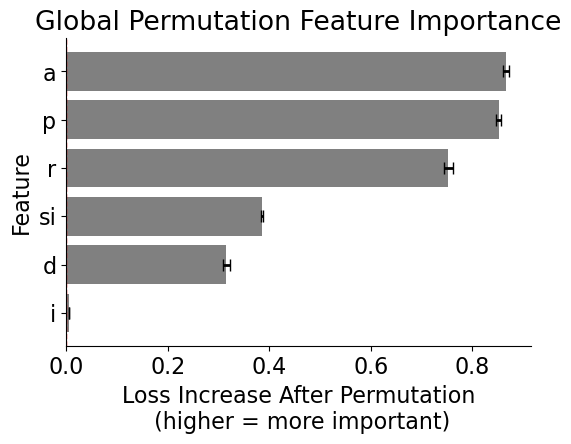

In [ ]:
plt.rcParams.update({"font.size": 16})
fig, ax = plt.subplots(figsize=(6, 4))
ax = sns.barplot(
    data=ranking,
    x="importance_mean",
    y="feature",
    ax=ax,
    color="grey",
)
# add error bars if present
if "importance_std" in ranking.columns:
    ax.errorbar(
        x=ranking["importance_mean"],
        y=range(len(ranking)),
        xerr=ranking["importance_std"],
        fmt="none",
        ecolor="black",
        capsize=4,
        lw=2
    )
ax.axvline(0, color="red", linestyle="--", linewidth=1)
ax.set_title("Global Permutation Feature Importance")# (missing %d%% data)" % k)

short_labels = ['si' if l.get_text() == 'stim_iter' else l.get_text()[:1] for l in ax.get_yticklabels()]
ax.set_yticklabels(short_labels, rotation=0)
ax.set_xlabel("Loss Increase After Permutation\n (higher = more important)")
ax.set_ylabel("Feature")
sns.despine(ax=ax)
# fig.savefig(
#     f"/Users/ccnlab/Documents/project_dl4rl/Tutorial/parameter_importance.png",
#     dpi=600,
#     bbox_inches="tight",
# )

# Trial-varying latent variable inference (LaseNet)

In [28]:
%matplotlib inline
import warnings; warnings.simplefilter('ignore')  # hide warnings

k = 0
feature_list = ['rewards', 'delay_since_last_stimuli', 'actions', 'prev_action',  'stimuli', 'isswitch'] 
test_features = extract_features_blockless(maksed_to_test_iter[k], feature_list, [])

num_test_agents = test_data['agentid'].nunique()
n_trial = test_data['trials'].nunique()
n_block = test_data['block_no'].nunique()
# qv = np.array(test_data[k]['rewards'] - test_data[k]['rpe_history'])
qv = np.array(masked_to_test_data[k]['rewards'] - masked_to_test_data[k]['rpe_history'])
test_labels = qv.astype(np.float32).reshape((num_test_agents, n_block*n_trial))

print(test_features.shape, test_labels.shape)

(500, 936, 6) (500, 936)


## Load trained model (LaseNet)

In [29]:
model_name = "lasenet_s123_RLF-6S3A_r-d-a-p-i-s_A27000_936t_B128_U256_D0.097_D0.013_D0.011_0.000696_model.keras"
gru_model = tf.keras.models.load_model(f"./models/{model_name}", compile=True)

## Evaluate

In [30]:
# X_test: (500, 936, 5), y_test: (500, 936)
feature_names = feature_list
# Generate sample_weight array: 0 for NaN values in test_labels, 1 otherwise
# For keras RNNs, sample_weight usually shape is (batch, timestep)
test_labels_dim = np.expand_dims(test_labels, axis=-1)

# 2. Create the weight mask (1 for valid, 0 for NaN)
sample_weight = (~np.isnan(test_labels_dim)).astype(np.float32)
sample_weight = np.squeeze(sample_weight, axis=-1) 

# 3. Fill NaNs with an absurd out-of-bounds dummy value.
# The sample_weight will multiply the loss for these steps by 0,
# completely erasing this -9999.0 from the final calculation.
test_labels_clean = np.nan_to_num(test_labels_dim, nan=-9999.0)
print(sample_weight.shape, test_labels_clean.shape)

ranking = permutation_importance_global_sequence(
    model=gru_model,     # already trained once
    X_val=test_features,
    y_val=test_labels_clean,
    feature_names=feature_names,
    n_repeats=3,
    batch_size=64,
    sample_weight=sample_weight,  # put mask here if you use padded timesteps
    shuffle_mode="within_sample",
    random_state=11
)

print(ranking)

(500, 936) (500, 936, 1)
Baseline loss: 0.043455831706523895
Permutation feature rewards
Permutation loss: 0.0736336037516594
Permutation loss: 0.07382845133543015
Permutation loss: 0.07375449687242508
Permutation feature delay_since_last_stimuli
Permutation loss: 0.05343954265117645
Permutation loss: 0.0536239817738533
Permutation loss: 0.05348275601863861
Permutation feature actions
Permutation loss: 0.04509740695357323
Permutation loss: 0.04507818818092346
Permutation loss: 0.04509603604674339
Permutation feature prev_action
Permutation loss: 0.044132400304079056
Permutation loss: 0.04411698132753372
Permutation loss: 0.04405870661139488
Permutation feature stimuli
Permutation loss: 0.04234521836042404
Permutation loss: 0.0423746258020401
Permutation loss: 0.04233893007040024
Permutation feature isswitch
Permutation loss: 0.04329494386911392
Permutation loss: 0.043292220681905746
Permutation loss: 0.04329283908009529
                    feature  importance_mean  importance_std  base

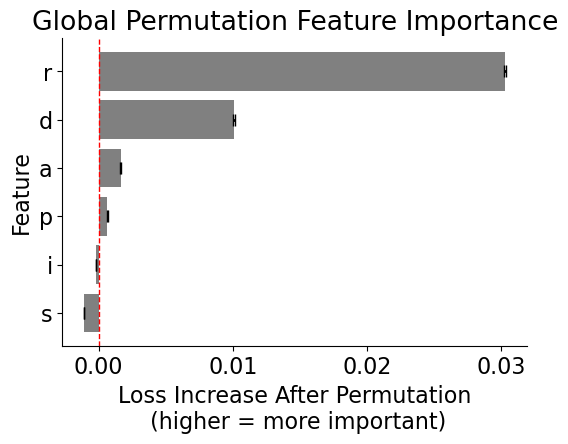

In [ ]:
plt.rcParams.update({"font.size": 16})

fig, ax = plt.subplots(figsize=(6, 4))
ax = sns.barplot(
    data=ranking,
    x="importance_mean",
    y="feature",
    color="grey",
    ax=ax,
)
# add error bars if present
if "importance_std" in ranking.columns:
    ax.errorbar(
        x=ranking["importance_mean"],
        y=range(len(ranking)),
        xerr=ranking["importance_std"],
        fmt="none",
        ecolor="black",
        capsize=4,
        lw=2
    )
ax.axvline(0, color="red", linestyle="--", linewidth=1)
ax.set_title(f"Global Permutation Feature Importance") # ({k}% missing)")
ax.set_xlabel("Loss Increase After Permutation\n (higher = more important)")
short_labels = [l.get_text()[:1] for l in ax.get_yticklabels()]
ax.set_yticklabels(short_labels, rotation=0)
ax.set_ylabel("Feature")
sns.despine(ax=ax)
# fig.savefig(
#     f"/Users/ccnlab/Documents/project_dl4rl/Tutorial/lasenet_importance.png",
#     dpi=600,
#     bbox_inches="tight",
# )